# Deforestation Risk in Kalimantan's Palm Oil Supply Chain (2018 to 2024)

**Final Project**

Batch: CODA-RMT-023

This notebook analyses deforestation risk and emissions exposure in Kalimantan to identify the top 5 high-risk kabupaten and the exporter groups sourcing from them.

## Background
Topic: SDG 15 (Life on Land)

- Oil palm expansion has been an important driver of deforestation in Indonesia for decades, accounting for one third of Indonesia's forest loss.

- In the past few years, deforestation for indsutrial palm oil has been concentrated in Kalimantan, where most of its provinces greatly contributed to Indonesia's deforestation since 2018.

- The major issue is that many exporters, whether they have zero-deforestation commitments or not, source palm oil from areas with similar deforestation rates. This indicates that commitments alone does not ensure lower deforestation risk, so buyers cannot rely solely on exporter commitments and require data on where exporters source the palm oil.

## Business Problem
Palm oil buyers (importers and refineries) are under growing pressure from markets and regulations to ensure that the palm oil they buy is deforestation-free. However, buyers do not have clear data that shows whether their sources have low deforestation risk. So despite exporters' commitments, buyers may source from kabupaten and exporters with high deforestation risk without realizing.

Stakeholder: the sustainability/procurement team of a company planning to buy palm oil from Kalimantan.

## Problem Statement
We help the sustainability/procurement team of a palm oil buying company avoid sourcing from high deforestation risk areas, by analysing Trase palm oil supply chain data from 2018 to 2024 joined with industrial palm oil deforestation data per province, to identify the top 5 high-risk kabupaten in Kalimantan and the exporter groups sourcing from them, so that these can be avoided in sourcing decisions within the next 1 year.

## Objective

Identify the top 5 high-risk kabupaten in Kalimantan and the exporter groups sourcing from them, so that the sustainability/procurement team of a palm oil buying company can avoid high deforestation risk in its sourcing decisions. The analysis will also show which product types these high-risk exporter groups trade, compare deforestation intensity by commitment status and product type, calculate the emissions exposure linked to the top 5 kabupaten, and measure how much of each province's industrial palm oil deforestation is linked to them, using the supporting province deforestation data.

Results will be shown in a Tableau dashboard with recommendations on which kabupaten and exporters to avoid.

Data Period: 2018 to 2024, includes the full range of the main dataset. The supporting dataset is filtered to the same years.

## Analysis Questions (5W+1H)
- What: What is the deforestation intensity of Kalimantan's palm oil supply chain, how much higher is it in the top 5 kabupaten, and which product type carries higher intensity? How much greenhouse gas emissions exposure is linked to the top 5 high-risk kabupaten?

- Where: Which kabupaten have the highest deforestation intensity and exposure, and which provinces do they belong to? Which provinces have the largest industrial palm oil deforestation?

- Who: Which exporter groups and importing countries source the most palm oil from the top 5 high-risk kabupaten, and which product types do these exporter groups trade? Which exporter groups have the lowest deforestation risk and can be recommended to buyers instead?

- When: When did industrial palm oil deforestation in each Kalimantan province rise or fall between 2018 and 2024, and did supply chain deforestation exposure change in the same years?

- Why: Why are some kabupaten riskier? Do they have a larger share of volume from exporters with None or Unknown commitment status, and are they in provinces with high industrial palm oil deforestation?

- How: How much of Kalimantan's deforestation exposure would be avoided if buyers stopped sourcing from the top 5 high-risk kabupaten?

## KPIs
1. Deforestation intensity: total exposure / total volume x 1,000 (ha per 1,000 t), calculated per group. Baseline: overall Kalimantan intensity.
2. Top 5 share of province deforestation (%): top 5 exposure / province industrial palm oil deforestation x 100
3. Top 5 volume share (%): top 5 volume / total volume x 100
4. Exposure avoided (%): top 5 exposure / total exposure x 100
5. Total emissions exposure: sum of emissions for the top 5 kabupaten

## Importing Library and Loading Data

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
palm = pd.read_csv('palm_oil_cleaned.csv')
defor = pd.read_csv('deforestation_cleaned.csv')
print(palm.shape)
print(defor.shape)

(588476, 11)
(125, 4)


In [3]:
print(palm['year'].min(), palm['year'].max())
print(defor['year'].min(), defor['year'].max())

2018 2024
2001 2025


palm oil data (main) period is already from 2018 to 2024 but the deforestation data (supporting) is not, so it needs to be filtered.

## Filtering Deforestation Data (2018 to 2024) and Joining Dataset

In [4]:
defor = defor [(defor['year'] >= 2018) & (defor['year'] <= 2024)]
print(defor.shape)

(35, 4)


In [5]:
df = palm.merge(defor, left_on=['year', 'province_of_production_trase_id'],
                right_on=['year', 'region_trase_id'], how='left')
df = df.drop(columns=['region', 'region_trase_id'])
print(df.shape)
print(df['annual_palm_deforestation_(industrial)_hectares'].isnull().sum())

(588476, 12)
0


In [6]:
df.head()

,year,province_of_production,province_of_production_trase_id,kabupaten_of_production,product_type,exporter_group,zero_deforestation_indonesia_palm_oil,country_of_first_import,palm_oil_deforestation_annual_exposure,volume,total_emission_exposure,annual_palm_deforestation_(industrial)_hectares
0,2018,KALIMANTAN BARAT,ID-61,KETAPANG,CRUDE PALM OIL,WINGS AGRO,NONE,INDIA,0.057658,214.026689,285.451339,5314.14
1,2018,KALIMANTAN BARAT,ID-61,KETAPANG,CRUDE PALM OIL,WINGS AGRO,NONE,MALAYSIA,0.009618,35.700866,47.614902,5314.14
2,2018,KALIMANTAN BARAT,ID-61,KETAPANG,CRUDE PALM OIL,WINGS AGRO,NONE,MALAYSIA,0.007694,28.560692,38.091922,5314.14
3,2018,KALIMANTAN BARAT,ID-61,KETAPANG,CRUDE PALM OIL,WINGS AGRO,NONE,SRI LANKA,0.000969,3.598647,4.799582,5314.14
4,2018,KALIMANTAN BARAT,ID-61,KETAPANG,CRUDE PALM OIL,INCASI RAYA (GUNAS),NONE,INDIA,0.422918,1569.868447,2093.762478,5314.14


Datasets have successfully been joined with 588,476 rows and no null values.

## Overall KPIs and Baseline Intensity

Deforestation intenisty = total exposure / total volume x 1,000 (ha per 1,000 tonnes), calculated per group.

In [7]:
total_volume = df['volume'].sum()
total_exposure = df['palm_oil_deforestation_annual_exposure'].sum()
baseline_intensity = total_exposure / total_volume * 1000
total_emissions = df['total_emission_exposure'].sum()

print('Total volume:', round(total_volume, 0))
print('Total exposure:', round(total_exposure, 2))
print('Baseline intensity:', round(baseline_intensity, 3))
print('Total emissions exposure:', round(total_emissions, 0))

Total volume: 130673200.0
Total exposure: 172418.71
Baseline intensity: 1.319
Total emissions exposure: 613309822.0


The baseline deforestation intenisty for Kalimantan (2018 to 2024) is 1.319 ha per 1,000 tonnes.

## Analysis

### 1. Where: Which kabupaten have the highest deforestation intensity and exposure, and which provinces do they belong to? Which provinces have the largest industrial palm oil deforestation?


Ranking Kabupaten by Deforestation Intensity, "UNKNOWN" kabupaten are excluded because they cannot be located or avoided.

In [8]:
kab = df[df['kabupaten_of_production'] != 'UNKNOWN']
kab = kab.groupby(['kabupaten_of_production', 'province_of_production'])[['volume', 'palm_oil_deforestation_annual_exposure']].sum().reset_index()
kab['intensity'] = kab['palm_oil_deforestation_annual_exposure'] / kab['volume'] * 1000
kab = kab.sort_values(by='intensity', ascending=False)
print(len(kab))
kab.head(10)

52


,kabupaten_of_production,province_of_production,volume,palm_oil_deforestation_annual_exposure,intensity
20,KOTA PALANGKARAYA,KALIMANTAN TENGAH,1.635602e+05,2280.576641,13.943350
22,KOTA SINGKAWANG,KALIMANTAN BARAT,9.500430e+04,689.877460,7.261539
13,KAPUAS HULU,KALIMANTAN BARAT,1.559025e+06,11294.992923,7.244910
37,NUNUKAN,KALIMANTAN UTARA,1.905025e+06,13115.771507,6.884830
27,KUTAI BARAT,KALIMANTAN TIMUR,3.300420e+06,22246.012717,6.740359
48,TANA TIDUNG,KALIMANTAN UTARA,4.986895e+05,3346.917697,6.711427
23,KOTABARU,KALIMANTAN SELATAN,3.302407e+06,20488.800907,6.204202
7,BERAU,KALIMANTAN TIMUR,2.861251e+06,16849.397129,5.888823
8,BULUNGAN,KALIMANTAN UTARA,1.090794e+06,5731.514553,5.254442
3,BARITO SELATAN,KALIMANTAN TENGAH,1.353755e+05,596.224018,4.404225


In [9]:
top5 = kab.head(5)
top5

,kabupaten_of_production,province_of_production,volume,palm_oil_deforestation_annual_exposure,intensity
20,KOTA PALANGKARAYA,KALIMANTAN TENGAH,1.635602e+05,2280.576641,13.943350
22,KOTA SINGKAWANG,KALIMANTAN BARAT,9.500430e+04,689.877460,7.261539
13,KAPUAS HULU,KALIMANTAN BARAT,1.559025e+06,11294.992923,7.244910
37,NUNUKAN,KALIMANTAN UTARA,1.905025e+06,13115.771507,6.884830
27,KUTAI BARAT,KALIMANTAN TIMUR,3.300420e+06,22246.012717,6.740359


In [10]:
top5_list = top5['kabupaten_of_production'].tolist()
print(top5_list)

['KOTA PALANGKARAYA', 'KOTA SINGKAWANG', 'KAPUAS HULU', 'NUNUKAN', 'KUTAI BARAT']


Kabupaten Ranking by Total Deforestation Exposure

In [11]:
kab.sort_values(by='palm_oil_deforestation_annual_exposure', ascending=False).head(10)

,kabupaten_of_production,province_of_production,volume,palm_oil_deforestation_annual_exposure,intensity
27,KUTAI BARAT,KALIMANTAN TIMUR,3.300420e+06,22246.012717,6.740359
23,KOTABARU,KALIMANTAN SELATAN,3.302407e+06,20488.800907,6.204202
7,BERAU,KALIMANTAN TIMUR,2.861251e+06,16849.397129,5.888823
37,NUNUKAN,KALIMANTAN UTARA,1.905025e+06,13115.771507,6.884830
13,KAPUAS HULU,KALIMANTAN BARAT,1.559025e+06,11294.992923,7.244910
16,KETAPANG,KALIMANTAN BARAT,1.122075e+07,11217.392817,0.999701
14,KATINGAN,KALIMANTAN TENGAH,2.256808e+06,8404.452913,3.724045
30,LAMANDAU,KALIMANTAN TENGAH,4.697048e+06,8350.372310,1.777792
40,PULANG PISAU,KALIMANTAN TENGAH,2.859524e+06,7347.295829,2.569412
9,GUNUNG MAS,KALIMANTAN TENGAH,1.984649e+06,6088.934522,3.068016


The top 5 high-risk kabupaten by deforestation intensity are Kota Palangkaraya, Kota Singkawang, Kapuas Hulu, Nunukan, and Kutai Barat, with intensities between 6.74 and 13.94 ha per 1,000 tonnes, compared with the Kalimantan baseline of 1.319. Kota Palangkaraya and Kota Singkawang have much smaller volumes than the others, so their intensity is high partly because of their low volume.

By total deforestation exposure, the top 5 are Kutai Barat, Kotabaru, Berau, Nunukan, and Kapuas Hulu. Kapuas Hulu, Nunukan and Kutai Barat appear in the top 5 of both rankings, so they are high risk by both intensity and total exposure.

### 2. Who: Which exporter groups and importing countries source the most palm oil from the top 5 high-risk kabupaten, and which product types do these exporter groups trade? Which exporter groups have the lowest deforestation risk and can be recommended to buyers instead?


Exporter groups and importing countries sourcing from the Top 5 Kabupaten.

In [12]:
top5_df = df[df['kabupaten_of_production'].isin(top5_list)]
print(top5_df.shape)

(20112, 12)


Exporter Groups Sourcing the Most Palm Oil from the Top 5

In [13]:
exp_top5 = top5_df.groupby('exporter_group')[['volume', 'palm_oil_deforestation_annual_exposure']].sum().reset_index()
exp_top5['intensity'] = exp_top5['palm_oil_deforestation_annual_exposure'] / exp_top5['volume'] * 1000
exp_top5.sort_values(by='volume', ascending=False).head(10)

,exporter_group,volume,palm_oil_deforestation_annual_exposure,intensity
10,DOMESTIC PROCESSING AND CONSUMPTION,4.331665e+06,37519.776785,8.661745
36,UNKNOWN,4.814609e+05,2746.080173,5.703641
32,SINAR MAS,4.300014e+05,516.394203,1.200913
28,ROYAL GOLDEN EAGLE,2.726998e+05,249.373487,0.914462
24,MUSIM MAS,2.066375e+05,36.836341,0.178266
17,KARYAMAS PLANTATION,2.046030e+05,2747.592236,13.428898
13,FIRST RESOURCES,1.674940e+05,57.291810,0.342053
22,LOUIS DREYFUS,1.624216e+05,995.793991,6.130922
12,FIMACORP,1.390028e+05,6.642420,0.047786
20,KPN CORP,1.311992e+05,696.126043,5.305871


Importing Countries of Palm Oil from the Top 5

In [14]:
country_top5 = top5_df.groupby('country_of_first_import')['volume'].sum().reset_index()
country_top5.sort_values(by='volume', ascending=False).head(10)

,country_of_first_import,volume
53,INDONESIA,4.331665e+06
19,CHINA (MAINLAND),5.659416e+05
71,MALAYSIA,4.771269e+05
52,INDIA,3.977029e+05
92,PAKISTAN,2.893067e+05
59,JAPAN,9.914624e+04
7,BANGLADESH,9.442073e+04
136,UNITED STATES,8.748575e+04
57,ITALY,7.927041e+04
116,SPAIN,7.397212e+04


Product Types Traded by Exporter Groups Sourcing from the Top 5

In [15]:
product_top5 = top5_df.groupby(['exporter_group', 'product_type'])['volume'].sum().reset_index()
product_top5.sort_values(by='volume', ascending=False).head(10)

,exporter_group,product_type,volume
11,DOMESTIC PROCESSING AND CONSUMPTION,CRUDE PALM OIL,4.331665e+06
42,SINAR MAS,REFINED PALM OIL,3.691576e+05
48,UNKNOWN,REFINED PALM OIL,3.025261e+05
35,ROYAL GOLDEN EAGLE,REFINED PALM OIL,2.685210e+05
29,MUSIM MAS,REFINED PALM OIL,2.066375e+05
19,KARYAMAS PLANTATION,CRUDE PALM OIL,2.046030e+05
47,UNKNOWN,CRUDE PALM OIL,1.789348e+05
15,FIRST RESOURCES,REFINED PALM OIL,1.665187e+05
27,LOUIS DREYFUS,REFINED PALM OIL,1.557869e+05
13,FIMACORP,CRUDE PALM OIL,1.390028e+05


'DOMESTIC PROCESSING AND CONSUMPTION', 'UNKNOWN', and 'UNKNOWN AFFILIATION' are not real exporter groups, but they are kept in the tables so that important data from other columns is not removed. 'INDONESIA' in the importing country column is domestic use.

Most palm oil from the top 5 kabupaten goes to domestic processing and consumption. Among real exporter groups, Sinar Mas, Royal Golden Eagle, Musim Mas, Karyamas Plantation, and First Resourcecs source the most. Outside Indonesia, the main importing countries are China Malaysia, India, and Pakistan. Domestic use is crude palm oil, while most exporter groups such as Sinar Mas, Royal Golden Eagle, and Musim Mas trade refined palm oil.

#### Lowest-Risk Exporter Groups (Recommended Alternatives)
Placeholder groups ar eleft out of this list because buyers cannot source from them. All real exporter groups are ranked from lowest to highest intensity, with volume shown so the size of each group can be seen.

In [16]:
placeholders = ['DOMESTIC PROCESSING AND CONSUMPTION', 'UNKNOWN', 'UNKNOWN AFFILIATION']
exp_all = df[~df['exporter_group'].isin(placeholders)]
exp_all = exp_all.groupby('exporter_group')[['volume', 'palm_oil_deforestation_annual_exposure']].sum().reset_index()
exp_all['intensity'] = exp_all['palm_oil_deforestation_annual_exposure'] / exp_all['volume'] * 1000
exp_all = exp_all.sort_values(by='intensity', ascending=True)
print(len(exp_all))
exp_all.head(15)

53


,exporter_group,volume,palm_oil_deforestation_annual_exposure,intensity
0,AHMAD ZAKI RESOURCES BERHAD,434.255995,0.000000,0.000000
21,IOI CORPORATION,4510.290996,0.000000,0.000000
30,LX INTERNATIONAL,31496.244648,0.000000,0.000000
32,MKH BERHAD,27501.682968,0.000000,0.000000
40,REA HOLDINGS,48009.403971,0.000000,0.000000
34,NPC RESOURCES BERHAD,4093.570000,0.000000,0.000000
48,TIANJIN JULONG,5886.845000,0.000000,0.000000
14,FIMACORP,139002.799778,6.642420,0.047786
18,HAYEL SAEED ANAM (HSA),298090.075003,19.544739,0.065567
7,CARGILL,644711.155343,61.523922,0.095429


Seven exporter groups have zero deforestation intensity, but their volumes are small. Groups such as Cargill and First Resources also have very low intensity while supplying much larger volumes, so they can replace more of the supply from high-risk sources.

### 3. What: What is the deforestation intensity of Kalimantan's palm oil supply chain, how much higher is it in the top 5 kabupaten, and which product type carries higher intensity? How much greenhouse gas emissions exposure is linked to the top 5 high-risk kabupaten?


Top 5 Kabupaten vs the Rest of Kalimantan

In [17]:
rest_df = df[~df['kabupaten_of_production'].isin(top5_list)]

top5_intensity = top5_df['palm_oil_deforestation_annual_exposure'].sum() / top5_df['volume'].sum() * 1000
rest_intensity = top5_df['palm_oil_deforestation_annual_exposure'].sum() / rest_df['volume'].sum() * 1000

print('Top 5 itnensity:', round(top5_intensity, 3))
print('Rest of Kalimantan intensity:', round(rest_intensity, 3))
print('Top 5 is', round(top5_intensity / rest_intensity, 1), 'times higher')

Top 5 itnensity: 7.066
Rest of Kalimantan intensity: 0.401
Top 5 is 17.6 times higher


The top 5 kabupaten have a deforestation intensity of 7.07 ha per 1,000 tonnes, about 7 times higher than the rest of Kalimantan (0.99).

Deforestation Intensity by Product Type

In [18]:
product = df.groupby('product_type')[['volume', 'palm_oil_deforestation_annual_exposure']].sum().reset_index()
product['intensity'] = product['palm_oil_deforestation_annual_exposure'] / product['volume'] * 1000
product

,product_type,volume,palm_oil_deforestation_annual_exposure,intensity
0,CRUDE PALM OIL,7.789221e+07,127683.122289,1.639228
1,REFINED PALM OIL,5.278099e+07,44735.586369,0.847570


Crde palm oil has a higher deforestation intensity (1.64) than refined palm oil (0.85)

### 4. Why: Why are some kabupaten riskier? Do they have a larger share of volume from exporters with None or Unknown commitment status?

Deforestation Intensity by Commitment Status

In [19]:
commit = df.groupby('zero_deforestation_indonesia_palm_oil')[['volume', 'palm_oil_deforestation_annual_exposure']].sum().reset_index()
commit['intensity'] = commit['palm_oil_deforestation_annual_exposure'] / commit['volume'] * 1000
commit.sort_values(by='intensity', ascending=False)

,zero_deforestation_indonesia_palm_oil,volume,palm_oil_deforestation_annual_exposure,intensity
3,ZERO DEFORESTATION,4.573578e+06,8290.720047,1.812743
2,UNKNOWN,7.570838e+07,124255.744910,1.641242
1,NONE,5.080991e+06,6261.325691,1.232304
0,NDPE COMMITMENT,4.531025e+07,33610.918010,0.741795


Exporters with Zero Deforestation commitments have the highest intensity (1.81), while NDPE has the lowest (0.74), showing that commitments alone do not guarantee lower deforestation risk.

Share of Volume by Commitment Status: Top 5 vs Rest of Kalimantan

In [20]:
commit_top5 = top5_df.groupby('zero_deforestation_indonesia_palm_oil')['volume'].sum().reset_index()
commit_top5['share'] = commit_top5['volume'] / top5_df['volume'].sum() * 100

commit_rest = rest_df.groupby('zero_deforestation_indonesia_palm_oil')['volume'].sum().reset_index()
commit_rest['share'] = commit_rest['volume'] / rest_df['volume'].sum() * 100

print('top 5')
print(commit_top5)

print()

print('rest')
print(commit_rest)


top 5
  zero_deforestation_indonesia_palm_oil        volume      share
0                       NDPE COMMITMENT  1.553403e+06  22.118690
1                                  NONE  2.835600e+05   4.037571
2                               UNKNOWN  5.039028e+06  71.750025
3                    ZERO DEFORESTATION  1.470422e+05   2.093713

rest
  zero_deforestation_indonesia_palm_oil        volume      share
0                       NDPE COMMITMENT  4.375685e+07  35.387618
1                                  NONE  4.797431e+06   3.879842
2                               UNKNOWN  7.066935e+07  57.152654
3                    ZERO DEFORESTATION  4.426535e+06   3.579886


The top 5 kabupaten have a larger share of volume with Unknown commitment status (71.8%) than the rest of Kalimantan (57.2%).

### 5. When: When did industrial palm oil deforestation in each Kalimantan province rise or fall between 2018 and 2024, and did supply chain deforestation exposure change in the same years?

In [21]:
prov_year = df.groupby(['year', 'province_of_production']).agg({'palm_oil_deforestation_annual_exposure': 'sum', 'annual_palm_deforestation_(industrial)_hectares': 'first'}).reset_index()
prov_year

,year,province_of_production,palm_oil_deforestation_annual_exposure,annual_palm_deforestation_(industrial)_hectares
0,2018,KALIMANTAN BARAT,5303.795803,5314.14
1,2018,KALIMANTAN SELATAN,3563.635055,3564.35
2,2018,KALIMANTAN TENGAH,11320.380391,11477.06
3,2018,KALIMANTAN TIMUR,17547.236994,17547.29
4,2018,KALIMANTAN UTARA,4791.086841,4791.09
5,2019,KALIMANTAN BARAT,7224.044864,7224.05
6,2019,KALIMANTAN SELATAN,1882.856213,1882.86
7,2019,KALIMANTAN TENGAH,5861.559224,6208.69
8,2019,KALIMANTAN TIMUR,9515.217494,9524.42
9,2019,KALIMANTAN UTARA,5065.042458,5065.04


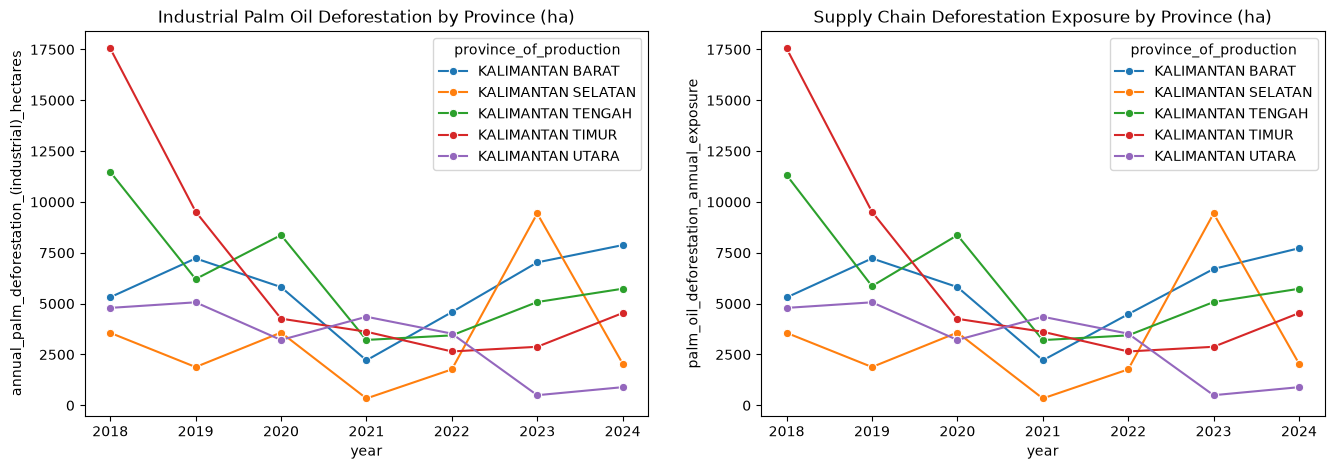

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.lineplot(data=prov_year, x='year', y='annual_palm_deforestation_(industrial)_hectares', hue='province_of_production', marker='o', ax=axes[0])
axes[0].set_title('Industrial Palm Oil Deforestation by Province (ha)')
sns.lineplot(data=prov_year, x='year', y='palm_oil_deforestation_annual_exposure', hue='province_of_production', marker='o', ax=axes[1])
axes[1].set_title('Supply Chain Deforestation Exposure by Province (ha)')
plt.show()


Supply chain deforestation exposure follows almost the same trend as industrial palm oil deforestation in every province from 2018 to 2024, so exposure moves in the same direction as deforestation.

### 6. Why: are they in provinces with high industrial palm oil deforestation?

In [23]:
prov_total = prov_year.groupby('province_of_production')[['annual_palm_deforestation_(industrial)_hectares']].sum().reset_index()
prov_total.sort_values(by='annual_palm_deforestation_(industrial)_hectares', ascending=False)

,province_of_production,annual_palm_deforestation_(industrial)_hectares
3,KALIMANTAN TIMUR,45016.57
2,KALIMANTAN TENGAH,43524.46
0,KALIMANTAN BARAT,40051.99
1,KALIMANTAN SELATAN,22615.85
4,KALIMANTAN UTARA,22341.88


In [24]:
top5[['kabupaten_of_production', 'province_of_production']]

,kabupaten_of_production,province_of_production
20,KOTA PALANGKARAYA,KALIMANTAN TENGAH
22,KOTA SINGKAWANG,KALIMANTAN BARAT
13,KAPUAS HULU,KALIMANTAN BARAT
37,NUNUKAN,KALIMANTAN UTARA
27,KUTAI BARAT,KALIMANTAN TIMUR


Kalimantan Timur, Kalimantan Tengah, Kalimantan Barat the largest industrial palm oil deforestation from 2018 to 2024. Four of the top 5 kabupaten are in these provinces, while Nunukan is in Kalimantan Utara, which has the lowest total deforestation.

### KPI 2: Top 5 Share of Province Deforestation

In [25]:
top5_prov = top5_df.groupby('province_of_production')['palm_oil_deforestation_annual_exposure'].sum().reset_index()
top5_prov = top5_prov.merge(prov_total, on='province_of_production')
top5_prov['share'] = top5_prov['palm_oil_deforestation_annual_exposure'] / top5_prov['annual_palm_deforestation_(industrial)_hectares'] * 100
top5_prov

,province_of_production,palm_oil_deforestation_annual_exposure,annual_palm_deforestation_(industrial)_hectares,share
0,KALIMANTAN BARAT,11984.870384,40051.99,29.923283
1,KALIMANTAN TENGAH,2280.576641,43524.46,5.239759
2,KALIMANTAN TIMUR,22246.012717,45016.57,49.417387
3,KALIMANTAN UTARA,13115.771507,22341.88,58.704870


The top 5 kabupaten are linked to 58.7% of Kalimantan Utara's industrial palm oil deforestation, 49.4% of Kalimantan Timur's, 29.9% of Kalimantan Barat's and 5.2% of Kalimantan Tengah's, from 2018 to 2024.

### 7. How: How much of Kalimantan's deforestation exposure would be avoided if buyers stopped sourcing from the top 5 high-risk kabupaten?

In [26]:
exposure_avoided = top5_df['palm_oil_deforestation_annual_exposure'].sum() / total_exposure * 100
volume_share = top5_df['volume'].sum() / total_volume * 100

print('Exposure avoided (%):', round(exposure_avoided, 2))
print('Top 5 volume share (%):', round(volume_share, 2))

Exposure avoided (%): 28.78
Top 5 volume share (%): 5.37


The top 5 kabupaten supply only 5.37% of Kalimantan's palm oil volume but are linked to 28.78% of its deforestation exposure. Avoiding them would remove almost 30% of the deforestation risk while only about 5% of supply would need to be replaced.

Emissions Exposure of the Top 5 Kabupaten

In [27]:
top5_emissions = top5_df['total_emission_exposure'].sum()
emissions_share = top5_emissions / total_emissions * 100

print('Top 5 emissions exposure:', round(top5_emissions, 0))
print('Top 5 share of emissions exposure (%):', round(emissions_share, 2))

Top 5 emissions exposure: 51176123.0
Top 5 share of emissions exposure (%): 8.34


The top 5 kabupaten are linked to 51,176,123 of emissions exposure, 8.34% of Kalimantan's total, which is higher than the 5.37% share of volume.

### KPI Summary

In [28]:
kpi = pd.DataFrame({
    'KPI': ['Baseline deforestation intensity (ha per 1,000 t)', 
            'Top 5 deforestation intensity (ha per 1,000 t)',
            'Top 5 volume share (%)',
            'Exposure avoided (%)',
            'Top 5 emissions exposure'],
    'Value': [round(baseline_intensity, 3),
              round(top5_intensity, 3),
              round(volume_share, 2),
              round(exposure_avoided, 2),
              round(top5_emissions, 0)]
})

kpi

,KPI,Value
0,"Baseline deforestation intensity (ha per 1,000 t)",1.319000e+00
1,"Top 5 deforestation intensity (ha per 1,000 t)",7.066000e+00
2,Top 5 volume share (%),5.370000e+00
3,Exposure avoided (%),2.878000e+01
4,Top 5 emissions exposure,5.117612e+07


In [29]:
top5_prov[['province_of_production', 'share']]

,province_of_production,share
0,KALIMANTAN BARAT,29.923283
1,KALIMANTAN TENGAH,5.239759
2,KALIMANTAN TIMUR,49.417387
3,KALIMANTAN UTARA,58.704870


KPI 2 is shown per province above, because each province has a different share. Kalimantan Selatan is not shown because none of the top 5 kabupaten are located there (0%).

## Conclusion

The analysis identified the top 5 high-risk kabupaten in Kalimantan (2018 to 2024) by deforestation intensity: Kota Palangkaraya, Kota Singkawang, Kapuas Hulu, Nunukan and Kutai Barat.

### Key Insights
1. **The top 5 kabupaten carry a large share of risk for a small share of supply:** Their deforestation intensity is 7.07 ha per 1,000 tonnes, about 7 times the rest of Kalimantan (0.99). They supply only 5.37% of Kalimantan's palm oil volume but are linked to 28.78% of its deforestation exposure and 8.34% of its emissions exposure. They are also linked to 58.7% of Kalimantan Utara's and 49.4% of Kalimantan Timur's industrial palm oil deforestation.
2. **Commitments alone do not guarantee lower deforestation risk:** Exporters with Zero Deforestation commitments have the highest intensity (1.81), while NDPE has the lowest (0.74). Most volume from the top 5 has Unknown commitment status (71.8%), higher than the rest of Kalimantan (57.2%).
3. **Crude palm oil and domestic supply carry higher risk:** Crude palm oil has about twice the intensity of refined palm oil (1.64 vs 0.85), and most palm oil from the top 5 kabupaten goes to domestic processing and consumption as crude palm oil. Supply chain exposure follows the same trend as industrial palm oil deforestation in each province, so it reflects deforestation on the ground.

### Recommendations
1. **Avoid or apply strict checks to sourcing from the top 5 kabupaten:** This would remove about 29% of Kalimantan's deforestation exposure while only about 5% of supply would need to be replaced. Kapuas Hulu, Nunukan and Kutai Barat should be the priority, as they are high risk by both intensity and total exposure.
2. **Shift sourcing to the lowest-risk exporter groups:** Seven exporter groups (such as REA Holdings and MKH Berhad) have zero deforestation intensity but small volumes, while groups such as Cargill and First Resources have very low intensity and larger volumes, so they can replace more supply. Buyers should still confirm that this supply does not come from the top 5 kabupaten.
3. **Do not rely on exporter commitments alone:** Buyers should ask suppliers for the kabupaten where their palm oil comes from and check it against deforestation data, giving extra attention to crude palm oil and to suppliers with Unknown or None commitment status.

### Limitations
- Exposure is a Trase estimate of deforestation linked to sourcing areas, not a measurement at each plantation, so results show deforestation risk, not proof of deforestation-free sourcing.
- The data covers the whole Kalimantan supply chain, not one company's suppliers.
- Some top 5 kabupaten (Kota Palangkaraya and Kota Singkawang) have small volumes, so their intensity is high partly because of their low volume.